# 멀티모달 RAG — 논문 PDF의 텍스트·표·그림으로 답하기

| 항목 | 내용 |
|---|---|
| 분석 PDF | `data/invest.pdf` — Song & Ermon, *Generative Modeling by Estimating Gradients of the Data Distribution* (arXiv:1907.05600, 23쪽) |
| 준비물 | OpenAI API 키(`.env`), Poppler, Tesseract |
| 결과물 | 한국어로 질문하면 논문의 텍스트·표·그림을 찾아 근거와 함께 답하는 RAG |

**사용법**: 위에서부터 셀을 하나씩 `Shift + Enter`로 실행하고, **출력이 남은 상태로 저장**한 뒤 커밋합니다.

## 목차

| 파트 | 내용 | 셀 |
|---|---|---|
| 0 | 전체 그림 | 개념 |
| 1 | 환경 준비 (임포트·API 키·설정값) | [1]~[3] |
| 2 | 1단계 추출: 텍스트 / 표 / 그림 | [4]~[6] |
| 3 | 2단계 요약: 텍스트·표·그림 요약 | [7]~[8] |
| 4 | 3단계 검색기: 요약 검색 → 원본 반환 | [9] |
| 5 | LangChain 체인: 번역 체인 / RAG 체인 | [10]~[11] |
| 6 | 전체 파이프라인 & 질의응답 5건 | [12]~[14] |
| 7 | Before / After: 텍스트 RAG vs 멀티모달 RAG | [15]~[16] |

---
# Part 0. 전체 그림

### 사전 준비 단계 (최초 1회)
```
 data/invest.pdf ──[1단계] partition_pdf(hi_res)──▶ 텍스트 블록 / 표(HTML) / 그림(data/figures/*.jpg)
                                                       │
                                     [2단계] 요약 (gpt-4o-mini, 그림은 비전 입력)
                                                       ▼
                    요약 ──▶ Chroma (검색용)      원본 ──▶ InMemoryStore (답변용)      ← doc_id 로 연결
```

### 질문할 때
```
 사용자(한국어) "Table 1에서 NCSN보다 점수가 높은 모델은?"
        │  ① 번역 체인                         ← LangChain LCEL
        ▼
 "Which model scores higher than NCSN in Table 1?"
        │  ② 요약 임베딩 검색 → doc_id 로 원본 꺼내기     ← Retrieval
        ▼
 [table p.7] <table>...</table>,  [image p.4] (base64) ...
        │  ③ 원본 텍스트·표 + 그림(data URL)으로 프롬프트 구성  ← Augmentation
        │  ④ RAG 체인 (gpt-4o-mini 비전)                   ← Generation
        │  ⑤ 번역 체인
        ▼
 한국어 답변 + 근거(종류·페이지) + 검색된 그림
```

### 왜 요약으로 검색하고 원본으로 생성하나?
- 표 HTML은 태그·숫자 위주라 그대로 임베딩하면 의미가 잘 안 잡히고, 그림은 텍스트 임베딩을 할 수 없습니다 → **요약(문장)으로 검색**
- 요약은 수치·세부가 빠질 수 있습니다 → **답변은 원본(표 전체, 그림 자체)으로 생성**

---
# Part 1. 환경 준비

In [20]:
# ============================================================
# [1] 라이브러리 임포트 & 환경 점검
# ============================================================
import os
import shutil
import sys
import time
from pathlib import Path

from dotenv import load_dotenv

# 프로젝트 루트(src/extract.py 가 있는 폴더)를 찾아 이동하고, src/ 를 임포트할 수 있게 합니다.
# 실행 위치(현재 폴더)가 notebooks/ 가 아니어도 동작하도록 노트북 파일 위치와 상위 폴더까지 찾습니다.
def find_project_root():
    candidates = [Path.cwd(), *Path.cwd().parents]
    notebook_file = os.environ.get("JPY_SESSION_NAME") or globals().get("__vsc_ipynb_file__")
    if notebook_file:
        nb_dir = Path(notebook_file).resolve().parent
        candidates = [nb_dir, *nb_dir.parents] + candidates
    for path in candidates:
        if (path / "src" / "extract.py").exists():
            return path
    raise FileNotFoundError(f"src/extract.py 를 찾지 못했습니다. 현재 위치: {Path.cwd()}")


PROJECT_ROOT = find_project_root()
os.chdir(PROJECT_ROOT)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
print("프로젝트 루트:", PROJECT_ROOT)

# --- 이미지 처리 & 노트북 출력 ---
from IPython.display import Markdown, display
from PIL import Image

# --- 프로젝트 모듈 (src/) ---
# 노트북은 src/ 의 함수를 불러와 실행·확인만 합니다. (같은 코드를 python -m src.retriever 로도 실행 가능)
from src.extract import load_pickle, run_extraction, save_pickle, split_texts
from src.summarize import load_or_summarize
from src.retriever import (QUESTIONS, ask_paper_rag, create_multi_vector_retriever,
                           create_rag_chain, create_text_retriever, create_translate_chain)

print("Python   :", sys.version.split()[0], "/", sys.prefix)
print("Poppler  :", "OK" if shutil.which("pdftoppm") else "✗ 미설치 — Path 확인 후 재시작")
print("Tesseract:", "OK" if shutil.which("tesseract") else "✗ 미설치 — Path 확인 후 재시작")
for mod in ["unstructured", "unstructured_inference", "langchain_classic", "chromadb", "tiktoken"]:
    try:
        __import__(mod)
        print(f"{mod:22s}: OK")
    except ImportError:
        print(f"{mod:22s}: ✗ 미설치")

프로젝트 루트: C:\workspaces\multimodal-rag
Python   : 3.11.9 / C:\workspaces\multimodal-rag\.venv
Poppler  : OK
Tesseract: OK
unstructured          : OK
unstructured_inference: OK
langchain_classic     : OK
chromadb              : OK
tiktoken              : OK


In [21]:
# ============================================================
# [2] OpenAI API 키 설정
# ============================================================
load_dotenv()                                   # .env 파일을 찾아 환경변수로 등록
OPENAI_API_KEY = os.getenv("OPENAI_API_KEY")    # 환경변수에서 키 읽기 (없으면 None)

if not OPENAI_API_KEY:
    raise ValueError("OPENAI_API_KEY 가 설정되지 않았습니다. .env 파일을 확인하세요.")

# 키 전체를 출력하면 보안상 위험하므로 앞 4자리만 확인용으로 출력
print("API 키 설정 완료:", OPENAI_API_KEY[:4] + "****")

API 키 설정 완료: sk-p****


In [22]:
# ============================================================
# [3] 설정값 (한 곳에서 관리)
# ============================================================
PDF_PATH      = PROJECT_ROOT / "data" / "invest.pdf"
FIGURES_DIR   = PROJECT_ROOT / "data" / "figures"      # 추출된 그림 저장 위치
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"    # 추출·요약 결과 저장 (Git 제외)

SUMMARY_MODEL     = "gpt-4o-mini"   # 텍스트·표·그림 요약 (비전 입력 지원)
RAG_MODEL         = "gpt-4o-mini"   # 원본 텍스트·표·그림을 보고 답변
TRANSLATION_MODEL = "gpt-4o-mini"   # 한↔영 번역
N_RESULTS         = 6               # 질문 하나당 검색할 벡터 수 (같은 원본은 하나로 합쳐짐)

REBUILD = False   # True 로 바꾸면 저장본을 무시하고 추출·요약을 처음부터 다시 실행

print("PDF 존재 여부:", PDF_PATH.exists(), PDF_PATH)
print("그림 폴더    :", FIGURES_DIR)

PDF 존재 여부: True C:\workspaces\multimodal-rag\data\invest.pdf
그림 폴더    : C:\workspaces\multimodal-rag\data\figures


---
# Part 2. 1단계 추출 — 텍스트 · 표 · 그림 (수업 01)

| 옵션 | 값 | 빼면 생기는 일 |
| --- | --- | --- |
| `strategy` | `"hi_res"` | 표·그림 영역을 인식하지 못함 |
| `extract_images_in_pdf` | `True` | 그림이 통째로 사라짐 |
| `infer_table_structure` | `True` | Table 1이 줄글로 뭉개짐 |
| `chunking_strategy` | `"by_title"` (4000 / 3800 / 2000) | 섹션 의미가 끊긴 블록이 생김 |

> ⏱️ hi_res는 몇 분 걸립니다. 결과는 `data/processed/extracted.pkl`에 저장되고, 다음부터는 저장본을 불러옵니다.

In [23]:
# ============================================================
# [4] 추출 실행 (저장본이 있으면 불러옴)
# ============================================================
EXTRACTED_PKL = PROCESSED_DIR / "extracted.pkl"

if EXTRACTED_PKL.exists() and not REBUILD:
    data = load_pickle(EXTRACTED_PKL)
    print("저장본 불러옴:", EXTRACTED_PKL)
else:
    start = time.time()
    # src/extract.py: extract_pdf_elements → categorize_elements → list_figures
    data = run_extraction(PDF_PATH, FIGURES_DIR)
    save_pickle(data, EXTRACTED_PKL)
    print(f"추출 완료 — {time.time() - start:.1f}초 소요")

texts, tables, images = data["texts"], data["tables"], data["images"]

print("요소 타입 분포 :", dict(data["type_counts"]))
print("텍스트 블록 수 :", len(texts))
print("표 블록 수     :", len(tables), "(표로 잘못 잡힌 블록은 categorize_elements 에서 제외)")
print("그림 수        :", len(images), [Path(i["image_path"]).name for i in images])

저장본 불러옴: C:\workspaces\multimodal-rag\data\processed\extracted.pkl
요소 타입 분포 : {'CompositeElement': 21, 'Table': 2, 'TableChunk': 1}
텍스트 블록 수 : 21
표 블록 수     : 1 (표로 잘못 잡힌 블록은 categorize_elements 에서 제외)
그림 수        : 24 ['figure-3-1.jpg', 'figure-4-2.jpg', 'figure-4-3.jpg', 'figure-5-4.jpg', 'figure-7-5.jpg', 'figure-8-6.jpg', 'figure-8-7.jpg', 'figure-8-8.jpg', 'figure-8-9.jpg', 'figure-16-10.jpg', 'figure-16-11.jpg', 'figure-16-12.jpg', 'figure-16-13.jpg', 'figure-16-14.jpg', 'figure-16-15.jpg', 'figure-17-16.jpg', 'figure-17-17.jpg', 'figure-18-18.jpg', 'figure-19-19.jpg', 'figure-20-20.jpg', 'figure-21-21.jpg', 'figure-21-22.jpg', 'figure-22-23.jpg', 'figure-23-24.jpg']


In [24]:
# ============================================================
# [5] 추출 결과 확인 — 텍스트 / 표
# ============================================================
print("=" * 60)
print(f"[텍스트 p.{texts[0]['page']}] 앞 300자")
print("=" * 60)
print(texts[0]["content"][:300], "\n")

for t in tables:
    print("=" * 60)
    print(f"[표 p.{t['page']}] HTML 앞 600자")
    print("=" * 60)
    print(t["content"][:600], "\n")

[텍스트 p.1] 앞 300자
0

2020

2

0

2

t c O 0 1 ] G L . s c [ 3 v 0 0 6 5 0 . 7 0 9

1

:

v

arXiv

i

X

r

a

Generative Modeling by Estimating Gradients of the Data Distribution 

[표 p.7] HTML 앞 600자
<table><tr><td>Model</td><td>Inception</td><td>FID</td></tr><tr><td colspan="3">CIFAR-10 Unconditional</td></tr><tr><td>PixelCNN [59]</td><td>4.60</td><td>65.93</td></tr><tr><td>PixelIQN [42]</td><td>5.29</td><td>49.46</td></tr><tr><td>EBM [12]</td><td>6.02</td><td>40.58</td></tr><tr><td>WGAN-GP [18]</td><td>7.86+.07</td><td>36.4</td></tr><tr><td>MoLM [45]</td><td>7.90+.10</td><td>18.9</td></tr><tr><td>SNGAN [36] ProgressiveGAN [25]</td><td>8.22 + .05 8.80 + .05</td><td>21.7 -</td></tr><tr><td>NCSN (Ours)</td><td>8.87+.12</td><td>25.32</td></tr><tr><td colspan="3">CIFAR-10 Conditional</td></tr 



['p.3', 'p.4', 'p.4', 'p.5', 'p.7', 'p.8']


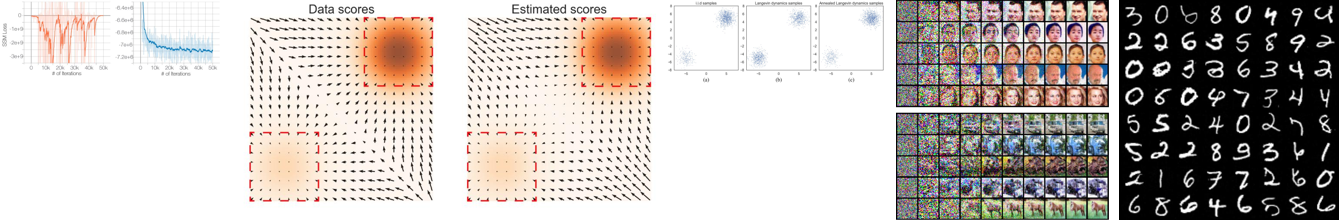

In [25]:
# ============================================================
# [6] 추출 결과 확인 — 그림 (FashionRAG show_image_grid)
# ============================================================
def show_image_grid(paths, thumb=220):
    """여러 이미지를 가로로 이어 붙인 '썸네일 한 장'으로 출력합니다."""
    imgs = [Image.open(p).convert("RGB") for p in paths]
    for im in imgs:
        im.thumbnail((thumb, thumb))
    # 가로로 나란히 붙일 빈 캔버스 생성 (흰 배경, 이미지 사이 10px 여백)
    canvas = Image.new("RGB", (sum(im.width for im in imgs) + 10 * (len(imgs) - 1),
                               max(im.height for im in imgs)), "white")
    x = 0
    for im in imgs:
        canvas.paste(im, (x, 0))
        x += im.width + 10
    display(canvas)


print([f"p.{i['page']}" for i in images[:6]])
show_image_grid([i["image_path"] for i in images[:6]])

---
# Part 3. 2단계 요약 — 검색용 색인 만들기

- 텍스트·표: `ChatPromptTemplate | ChatOpenAI | StrOutputParser` (LCEL)
- 그림: 같은 LCEL 체인의 user 메시지에 `data:image/jpeg;base64,...` 이미지 블록을 넣어 비전 모델로 요약
- 논문이 영어이므로 **요약 프롬프트와 요약도 영어**로 만듭니다 (질문은 Part 5의 번역 체인으로 영어로 바꿈)

- 요약이 곧 검색 색인이므로 **수치·설정값을 빠짐없이** 남기도록 지시합니다. 표는 모든 행의 모든 열 값을 나열하게 합니다.
- 그림은 캡션이 본문 쪽에 있으므로, **같은 페이지의 본문을 함께 넣어** 그림 번호와 표시(빨간 사각형 등)의 의미까지 요약하게 합니다.

> 결과는 `data/processed/summaries.pkl`에 저장해 API 비용을 다시 쓰지 않게 합니다.

In [26]:
# ============================================================
# [7] 요약 실행 (저장본이 있고 추출 결과와 개수가 맞으면 불러옴)
# ============================================================
# src/summarize.py: 텍스트·표 요약 + 그림 요약(같은 페이지 본문·캡션 함께 전달)
SUMMARY_PKL = PROCESSED_DIR / "summaries.pkl"

start = time.time()
summaries = load_or_summarize(data, rebuild=REBUILD, model=SUMMARY_MODEL, pkl_path=SUMMARY_PKL)
print(f"요약 준비 완료 — {time.time() - start:.1f}초 ({SUMMARY_PKL})")

text_summaries, table_summaries, image_summaries = summaries["texts"], summaries["tables"], summaries["images"]
print(f"텍스트 요약 {len(text_summaries)}개 / 표 요약 {len(table_summaries)}개 / 그림 요약 {len(image_summaries)}개")

요약 준비 완료 — 0.0초 (C:\workspaces\multimodal-rag\data\processed\summaries.pkl)
텍스트 요약 21개 / 표 요약 1개 / 그림 요약 24개


In [27]:
# ============================================================
# [8] 요약 결과 확인
# ============================================================
print(f"[텍스트 요약 p.{texts[0]['page']}]\n{text_summaries[0]}\n")
for t, s in zip(tables, table_summaries):
    print(f"[표 요약 p.{t['page']}]\n{s}\n")
for img, s in list(zip(images, image_summaries))[:4]:
    print(f"[그림 요약 {Path(img['image_path']).name}]\n{s}\n")

[텍스트 요약 p.1]
The text provided does not contain any specific details, numbers, hyperparameters, experimental settings, dataset names, model names, or figure/table references. It appears to be a citation or reference to a research paper titled "Generative Modeling by Estimating Gradients of the Data Distribution," published in 2020. The text includes some formatting artifacts and does not provide substantive content for summarization. Therefore, no detailed summary can be created from the given text.

[표 요약 p.7]
The table compares various models based on their performance metrics, specifically Inception scores and FID (Fréchet Inception Distance) values, for two different settings: CIFAR-10 Unconditional and CIFAR-10 Conditional.

### CIFAR-10 Unconditional
- PixelCNN [59]: Inception 4.60, FID 65.93
- PixelIQN [42]: Inception 5.29, FID 49.46
- EBM [12]: Inception 6.02, FID 40.58
- WGAN-GP [18]: Inception 7.86+.07, FID 36.4
- MoLM [45]: Inception 7.90+.10, FID 18.9
- SNGAN [36] Progressi

---
# Part 4. 3단계 검색기 — 요약으로 찾고 원본을 돌려받기 (rag-parser)

| 저장소 | 넣는 것 | 역할 |
|---|---|---|
| `vectorstore` (Chroma) | 요약 임베딩 + 텍스트·표 원문 임베딩 | 검색 대상 |
| `docstore` (InMemoryStore) | 원본: 텍스트, 표 HTML, 그림 base64 | 답변 재료 |

`MultiVectorRetriever`가 검색 결과의 `doc_id`로 원본을 꺼내 돌려줍니다.

- 원본 하나에 벡터를 **여러 개**(요약 + 원문) 연결합니다. 요약에서 빠진 세부 수치도 원문 벡터로 검색되게 하기 위함입니다.
- 같은 `doc_id`가 여러 번 걸려도 원본은 한 번만 돌려줍니다.

In [9]:
# ============================================================
# [9] 다중 벡터 검색기 생성 & 검색 테스트
# ============================================================
mm_retriever = create_multi_vector_retriever(
    [(texts, text_summaries), (tables, table_summaries), (images, image_summaries)],
    k=N_RESULTS,
)

# '요약'으로 찾았지만 돌려받는 것은 '원본'입니다.
docs = mm_retriever.invoke("Inception and FID scores of NCSN on CIFAR-10")
for d in docs:
    kind, page = d.metadata["kind"], d.metadata["page"]
    preview = "(그림 base64 원본)" if kind == "image" else d.page_content[:120].replace("\n", " ")
    print(f"[{kind} p.{page}] {preview}")

[table p.7] <table><tr><td>Model</td><td>Inception</td><td>FID</td></tr><tr><td colspan="3">CIFAR-10 Unconditional</td></tr><tr><td>
[text p.15] B Additional experimental details  B.1 Toy experiments  For the results in Fig. 1, we train a ResNet with sliced score m
[text p.7] 5 Experiments  In this section, we demonstrate that our NCSNs are able to produce high quality image samples on several 


---
# Part 5. LangChain 체인 — 번역 체인 & RAG 체인 (FashionRAG)

> 체인 코드는 `src/retriever.py`에 있고, 노트북에서는 불러와서 실행합니다.

```
 {"text": ..., "target_lang": ...}  ─ ChatPromptTemplate ─▶ [System, Human] ─ ChatOpenAI ─▶ AIMessage ─ StrOutputParser ─▶ str
```

In [10]:
# ============================================================
# [10] 번역 체인 (LCEL: 프롬프트 | 모델 | 파서) — src/retriever.py create_translate_chain
# ============================================================
translation_chain = create_translate_chain(TRANSLATION_MODEL)


def translate(text, target_lang):
    """text 를 target_lang(예: 'English', 'Korean')으로 번역한 문자열을 반환합니다."""
    return translation_chain.invoke({"text": text, "target_lang": target_lang})


print(translate("Table 1에서 NCSN의 FID는 얼마인가요?", "English"))

What is the FID of NCSN in Table 1?


In [11]:
# ============================================================
# [11] RAG 체인: 원본 텍스트·표 + 그림을 함께 LLM 에 전달 — src/retriever.py create_rag_chain
# ============================================================
# system : 제공된 근거로만 답하고, 근거가 없으면 없다고 말하기 (PDF OCR 깨짐 안내 포함)
# user   : 질문 + 원본 텍스트·표(context)
# image_messages : 검색된 그림을 data URL 이미지 블록으로 담은 메시지 (없으면 비어 있음)
rag_chain = create_rag_chain(RAG_MODEL)
print("RAG 체인 준비 완료")

RAG 체인 준비 완료


---
# Part 6. 전체 파이프라인 & 질의응답 5건

| 단계 | 함수 | RAG 역할 |
|---|---|---|
| ① 질문 번역 | `translate(query_ko, "English")` | 전처리 |
| ② 검색 | `retriever.invoke(query_en)` | **R**etrieval |
| ③ 프롬프트 입력 구성 | `format_prompt_inputs(docs, query_en)` | **A**ugmentation |
| ④ 답변 생성 | `rag_chain.invoke(prompt_input)` | **G**eneration |
| ⑤ 답변 번역 | `translate(answer_en, "Korean")` | 후처리 |

In [12]:
# ============================================================
# [12] 전체 파이프라인: 한국어 질문 -> 번역 -> 검색 -> RAG 체인 -> 번역 -> 출력
# ============================================================
# ①~⑤ 는 src/retriever.py ask_paper_rag 에서 실행하고, 노트북에서는 결과를 보기 좋게 출력합니다.
def ask_and_show(query_ko, retriever, show=True):
    r = ask_paper_rag(query_ko, retriever, translate_chain=translation_chain, rag_chain=rag_chain)
    if show:
        print("질문        :", r["query_ko"])
        print("번역된 질문 :", r["query_en"])
        print("근거 원본   :", r["sources"])
        display(Markdown(r["answer_ko"]))
        image_paths = [d.metadata["image_path"] for d in r["docs"] if d.metadata["kind"] == "image"]
        if image_paths:
            show_image_grid(image_paths)
    return r


============================== Q1 ==============================
질문        : CIFAR-10 unconditional 설정에서 NCSN의 Inception score와 FID는 각각 얼마인가요?
번역된 질문 : What are the Inception score and FID of NCSN in the CIFAR-10 unconditional setting?
근거 원본   : table p.7, text p.13, text p.15


CIFAR-10 무조건 설정에서 NCSN의 Inception 점수는 8.87+.12이고 FID는 25.32입니다.


============================== Q2 ==============================
질문        : Table 1에서 Inception score가 NCSN보다 높은 모델은 무엇이고, 어떤 설정인가요?
번역된 질문 : Which model in Table 1 has a higher Inception score than NCSN, and what is the configuration?
근거 원본   : table p.7, text p.13, text p.6, text p.14


표 1에서 모델 "MoLM [45]"는 NCSN보다 더 높은 Inception 점수를 가지고 있습니다. MoLM의 Inception 점수는 7.90+.10이며, NCSN (우리 모델)의 Inception 점수는 8.87+.12입니다. MoLM의 구성은 "CIFAR-10 Unconditional" 범주에 해당합니다.


============================== Q3 ==============================
질문        : Figure 2에서 빨간 사각형으로 표시된 영역은 무엇을 의미하나요?
번역된 질문 : What does the area marked with a red rectangle in Figure 2 signify?
근거 원본   : image p.16, image p.5, image p.4, image p.20, image p.17, image p.16


그림 2에서 빨간 사각형으로 표시된 영역은 추정된 점수가 로그 데이터 밀도의 실제 기울기에 가까운 지역을 강조합니다. 이는 점수 추정이 데이터 분포의 모드 근처, 즉 데이터 밀도가 높은 곳에서 주로 신뢰할 수 있음을 나타냅니다.

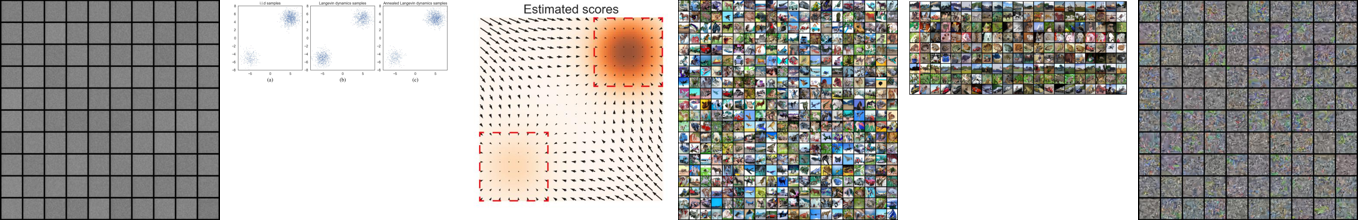


============================== Q4 ==============================
질문        : Figure 3에서 annealed Langevin dynamics와 일반 Langevin dynamics의 결과는 어떻게 다른가요?
번역된 질문 : How do the results of annealed Langevin dynamics differ from those of regular Langevin dynamics in Figure 3?
근거 원본   : text p.7, text p.4, image p.5, text p.15


어닐링된 랑주뱅 역학의 결과는 일반 랑주뱅 역학의 결과와 다릅니다. 어닐링된 랑주뱅 역학은 혼합 분포의 두 모드 간의 상대적인 가중치를 성공적으로 회복하는 반면, 일반 랑주뱅 역학은 그렇지 못합니다. 설명된 실험의 맥락에서, 일반 랑주뱅 역학은 모드 간의 상대 밀도가 잘못된 샘플을 생성하며, 이는 주로 한 사분면에 분산된 분포로 나타납니다. 반면, 어닐링된 랑주뱅 역학은 적절한 사분면에 더 집중된 분포를 생성하여 기본 혼합 분포를 정확하게 반영합니다. 이는 어닐링된 랑주뱅 역학이 잘 분리된 모드가 있는 분포에서 샘플링하는 데 더 효과적임을 보여줍니다. 특히, 모드 간에 저밀도 영역이 존재할 때 더욱 그렇습니다.

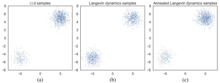


============================== Q5 ==============================
질문        : 이미지 생성 실험에서 노이즈 수준 σ는 몇 개, 어떤 범위로 설정했나요?
번역된 질문 : In the image generation experiment, how many noise levels σ were set and what range were they in?
근거 원본   : text p.5, text p.7, image p.3, text p.15


이미지 생성 실험에서는 10가지 서로 다른 노이즈 수준 \( \sigma \)가 설정되었으며, 범위는 \( \sigma_0 = 1 \)에서 \( \sigma_9 = 0.01 \)까지입니다.

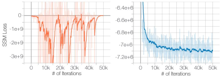

In [13]:
# ============================================================
# [13] 질의응답 5건 (질문 목록: src/retriever.py QUESTIONS)
# ============================================================
mm_results = []
for i, q in enumerate(QUESTIONS, start=1):
    print(f"\n{'=' * 30} Q{i} {'=' * 30}")
    mm_results.append(ask_and_show(q, mm_retriever))

In [14]:
# ============================================================
# [14] README 에 붙여 넣을 질의응답 표
# ============================================================
def one_line(s):
    return s.replace("\n", " ").replace("|", "\\|")

print("| # | 질문 | 답변 | 근거가 된 원본 종류 |")
print("| --- | --- | --- | --- |")
for i, r in enumerate(mm_results, start=1):
    kinds = ", ".join(sorted({d.metadata["kind"] for d in r["docs"]}))
    print(f"| {i} | {one_line(r['query_ko'])} | {one_line(r['answer_ko'])} | {kinds} ({r['sources']}) |")

| # | 질문 | 답변 | 근거가 된 원본 종류 |
| --- | --- | --- | --- |
| 1 | CIFAR-10 unconditional 설정에서 NCSN의 Inception score와 FID는 각각 얼마인가요? | CIFAR-10 무조건 설정에서 NCSN의 Inception 점수는 8.87+.12이고 FID는 25.32입니다. | table, text (table p.7, text p.13, text p.15) |
| 2 | Table 1에서 Inception score가 NCSN보다 높은 모델은 무엇이고, 어떤 설정인가요? | 표 1에서 모델 "MoLM [45]"는 NCSN보다 더 높은 Inception 점수를 가지고 있습니다. MoLM의 Inception 점수는 7.90+.10이며, NCSN (우리 모델)의 Inception 점수는 8.87+.12입니다. MoLM의 구성은 "CIFAR-10 Unconditional" 범주에 해당합니다. | table, text (table p.7, text p.13, text p.6, text p.14) |
| 3 | Figure 2에서 빨간 사각형으로 표시된 영역은 무엇을 의미하나요? | 그림 2에서 빨간 사각형으로 표시된 영역은 추정된 점수가 로그 데이터 밀도의 실제 기울기에 가까운 지역을 강조합니다. 이는 점수 추정이 데이터 분포의 모드 근처, 즉 데이터 밀도가 높은 곳에서 주로 신뢰할 수 있음을 나타냅니다. | image (image p.16, image p.5, image p.4, image p.20, image p.17, image p.16) |
| 4 | Figure 3에서 annealed Langevin dynamics와 일반 Langevin dynamics의 결과는 어떻게 다른가요? | 어닐링된 랑주뱅 역학의 결과는 일반 랑주뱅 역학의 결과와 다릅니다. 어닐링된 랑주뱅 역학은 혼합 분포의 두 모드 간의 상대적인 가중치를 성공적으로 회복하는 반면, 일반 랑주뱅 역학은 그렇지 못합니다. 설명된

---
# Part 7. Before / After — 텍스트 RAG vs 멀티모달 RAG

| 구분 | 검색 대상 | 답변 재료 |
|---|---|---|
| **Before (텍스트 RAG)** | 텍스트를 2000토큰 / overlap 200으로 자른 청크 원문 (수업 01 [8]) | 텍스트 청크만 |
| **After (멀티모달 RAG)** | 텍스트·표·그림 요약 + 텍스트·표 원문 | 원본 텍스트 · 표 HTML · 그림 |

번역 체인, RAG 체인, `N_RESULTS`는 같고 **검색 대상만** 다릅니다.

In [15]:
# ============================================================
# [15] Before: 텍스트만 쓰는 RAG 로 같은 질문 실행 & 비교
# ============================================================
texts_2k_token = split_texts(texts)    # 수업 01 [8]: 2000토큰 / overlap 200
print("텍스트 청크 수:", len(texts_2k_token))

text_retriever = create_text_retriever(texts_2k_token, k=N_RESULTS)
text_results = [ask_and_show(q, text_retriever, show=False) for q in QUESTIONS]

for i, (before, after) in enumerate(zip(text_results, mm_results), start=1):
    print(f"\n{'=' * 30} Q{i} {'=' * 30}")
    print("질문:", before["query_ko"])
    print(f"\n[Before 텍스트 RAG]   근거: {before['sources']}")
    print(before["answer_ko"])
    print(f"\n[After 멀티모달 RAG]  근거: {after['sources']}")
    print(after["answer_ko"])

텍스트 청크 수: 9

============================== Q1 ==============================
질문: CIFAR-10 unconditional 설정에서 NCSN의 Inception score와 FID는 각각 얼마인가요?

[Before 텍스트 RAG]   근거: text, text, text, text, text, text
CIFAR-10 무조건 설정에서 NCSN은 8.87의 Inception 점수와 25.32의 FID 점수를 달성합니다.

[After 멀티모달 RAG]  근거: table p.7, text p.13, text p.15
CIFAR-10 무조건 설정에서 NCSN의 Inception 점수는 8.87+.12이고 FID는 25.32입니다.

============================== Q2 ==============================
질문: Table 1에서 Inception score가 NCSN보다 높은 모델은 무엇이고, 어떤 설정인가요?

[Before 텍스트 RAG]   근거: text, text, text, text, text, text
제공된 맥락에는 답이 포함되어 있지 않습니다.

[After 멀티모달 RAG]  근거: table p.7, text p.13, text p.6, text p.14
표 1에서 모델 "MoLM [45]"는 NCSN보다 더 높은 Inception 점수를 가지고 있습니다. MoLM의 Inception 점수는 7.90+.10이며, NCSN (우리 모델)의 Inception 점수는 8.87+.12입니다. MoLM의 구성은 "CIFAR-10 Unconditional" 범주에 해당합니다.

============================== Q3 ==============================
질문: Figure 2에서 빨간 사각형으로 표시된 영역은 무엇을 의미하나요?

[Before 텍스트 RAG]   근거: text, text, text, tex

In [16]:
# ============================================================
# [16] README 에 붙여 넣을 Before / After 비교 표
# ============================================================
print("| # | 질문 | Before (텍스트 RAG) | After (멀티모달 RAG) |")
print("| --- | --- | --- | --- |")
for i, (b, a) in enumerate(zip(text_results, mm_results), start=1):
    a_kinds = ", ".join(sorted({d.metadata["kind"] for d in a["docs"]}))
    print(f"| {i} | {one_line(b['query_ko'])} | {one_line(b['answer_ko'])} (근거: text) "
          f"| {one_line(a['answer_ko'])} (근거: {a_kinds}) |")

| # | 질문 | Before (텍스트 RAG) | After (멀티모달 RAG) |
| --- | --- | --- | --- |
| 1 | CIFAR-10 unconditional 설정에서 NCSN의 Inception score와 FID는 각각 얼마인가요? | CIFAR-10 무조건 설정에서 NCSN은 8.87의 Inception 점수와 25.32의 FID 점수를 달성합니다. (근거: text) | CIFAR-10 무조건 설정에서 NCSN의 Inception 점수는 8.87+.12이고 FID는 25.32입니다. (근거: table, text) |
| 2 | Table 1에서 Inception score가 NCSN보다 높은 모델은 무엇이고, 어떤 설정인가요? | 제공된 맥락에는 답이 포함되어 있지 않습니다. (근거: text) | 표 1에서 모델 "MoLM [45]"는 NCSN보다 더 높은 Inception 점수를 가지고 있습니다. MoLM의 Inception 점수는 7.90+.10이며, NCSN (우리 모델)의 Inception 점수는 8.87+.12입니다. MoLM의 구성은 "CIFAR-10 Unconditional" 범주에 해당합니다. (근거: table, text) |
| 3 | Figure 2에서 빨간 사각형으로 표시된 영역은 무엇을 의미하나요? | 그림 2에서 빨간 사각형으로 표시된 영역은 추정된 점수 ∇x logpdata(x)가 추정된 점수 sθ(x)와 거의 동일한 지역을 강조합니다. 이는 점수 추정이 데이터 분포 pdata의 모드 근처, 즉 데이터 밀도가 높은 곳에서만 신뢰할 수 있음을 나타냅니다. (근거: text) | 그림 2에서 빨간 사각형으로 표시된 영역은 추정된 점수가 로그 데이터 밀도의 실제 기울기에 가까운 지역을 강조합니다. 이는 점수 추정이 데이터 분포의 모드 근처, 즉 데이터 밀도가 높은 곳에서 주로 신뢰할 수 있음을 나타냅니다. (근거: image) |
| 4 | Figure 3에서 annealed Langevin dynam